# Laboratorio #7 — NLP end-to-end y Embeddings

**CC3092 Deep Learning y Sistemas Inteligentes**

Pipeline completo: texto crudo → tokens → IDs → embeddings (SGNS propio en PyTorch, Word2Vec de gensim,
GloVe preentrenado) → aritmética vectorial → clasificación de AG News.

- **Corpus de embeddings:** WikiText-103 (raw)
- **Clasificación:** AG News (4 clases)
- **Benchmarks:** `questions-words.txt`, `wordsim353.tsv`, `simlex999.txt` (en `data/`)

## 0. Imports y configuración

In [1]:
import re
import time
import json
import pickle
import random
import collections
import io
import contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from gensim.models import Word2Vec, KeyedVectors
import gensim.downloader as api

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA = Path("data")
DATA.mkdir(exist_ok=True)
(DATA / "vectors").mkdir(exist_ok=True)
DEVICE = torch.device("cpu")  # SGNS con tablas sparse: CPU rinde mejor que MPS (gathers pequeños, overhead de kernels)
N_WORKERS = 8                 # hilos para gensim
CORPUS_TOKENS = 20_000_000    # prefijo de WikiText-103 usado como corpus principal (de ~100M)
MIN_COUNT = 5
print("torch", torch.__version__, "| device", DEVICE)

torch 2.14.1 | device cpu


## Fase 1 — Exploración y preprocesamiento

### 1.1 Carga de WikiText-103

El formato *raw* ya viene separado por espacios, con marcas propias: encabezados `= Título =`, y
`@-@`, `@,@`, `@.@` para guiones/comas/puntos dentro de palabras o números. Se limpian al normalizar.

In [2]:
wiki = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
lines = [l for l in wiki["train"]["text"] if l.strip() and not l.lstrip().startswith("=")]  # fuera líneas vacías y encabezados
print(f"{len(wiki['train']):,} líneas totales -> {len(lines):,} párrafos")
print(lines[1][:300])

1,801,350 líneas totales -> 859,532 párrafos
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers . Character designer Raita Hon


### 1.2 Tokenizador propio vs spaCy vs NLTK

Pipeline propio: minúsculas → resolver marcas `@x@` → regex que separa palabras (con contracciones tipo
`don't`), números y signos de puntuación. Para embeddings se descarta la puntuación y los números se
colapsan a `<num>` (un vector por cada año/cifra solo diluye el vocabulario).

In [3]:
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)*|[^\sa-z\d]")
AT_RE = re.compile(r" @(.)@ ")

def tokenize(text, keep_punct=False):
    """texto crudo -> lista de tokens. keep_punct=True mantiene signos (solo para comparar tokenizadores)."""
    text = AT_RE.sub(r"\1", text.lower())  # "1 @,@ 000" -> "1,000", "well @-@ known" -> "well-known"
    toks = WORD_RE.findall(text)
    toks = ["<num>" if t[0].isdigit() else t for t in toks]
    return toks if keep_punct else [t for t in toks if t[0].isalpha() or t == "<num>"]

print(tokenize(lines[1][:200], keep_punct=True))

['the', 'game', 'began', 'development', 'in', '<num>', ',', 'carrying', 'over', 'a', 'large', 'portion', 'of', 'the', 'work', 'done', 'on', 'valkyria', 'chronicles', 'ii', '.', 'while', 'it', 'retained', 'the', 'standard', 'features', 'of', 'the', 'series', ',', 'it', 'also', 'underwent', 'multiple', 'adju']


In [4]:
import spacy
from nltk.tokenize import NLTKWordTokenizer

nlp = spacy.blank("en")  # solo el tokenizador de spaCy, sin modelo (el resto del pipeline no se usa aquí)
nltk_tok = NLTKWordTokenizer()
sample = lines[:3000]

def run(fn):
    t = time.time()
    out = [fn(s) for s in sample]
    return out, time.time() - t

res = {
    "propio (regex)": run(lambda s: tokenize(s, keep_punct=True)),
    "spaCy (blank en)": run(lambda s: [t.text.lower() for t in nlp.make_doc(s)]),
    "NLTK (Treebank)": run(lambda s: [t.lower() for t in nltk_tok.tokenize(AT_RE.sub(r"\1", s))]),
}
rows = []
for name, (toks, secs) in res.items():
    flat = [t for d in toks for t in d]
    rows.append({"tokenizador": name, "tokens": len(flat), "vocab": len(set(flat)),
                 "seg/3000 párrafos": round(secs, 2)})
pd.DataFrame(rows)

,tokenizador,tokens,vocab,seg/3000 párrafos
0,propio (regex),332870,23450,0.04
1,spaCy (blank en),334540,24638,1.04
2,NLTK (Treebank),319911,26614,0.31


In [5]:
ex = "The U.S. president's well-known \"state-of-the-art\" plan costs $1,000.50 -- isn't cheap!"
for name, fn in {"propio": lambda s: tokenize(s, True),
                 "spaCy": lambda s: [t.text for t in nlp.make_doc(s)],
                 "NLTK": nltk_tok.tokenize}.items():
    print(f"{name:7s}", fn(ex))

propio  ['the', 'u', '.', 's', '.', "president's", 'well', '-', 'known', '"', 'state', '-', 'of', '-', 'the', '-', 'art', '"', 'plan', 'costs', '$', '<num>', '-', '-', "isn't", 'cheap', '!']
spaCy   ['The', 'U.S.', 'president', "'s", 'well', '-', 'known', '"', 'state', '-', 'of', '-', 'the', '-', 'art', '"', 'plan', 'costs', '$', '1,000.50', '--', 'is', "n't", 'cheap', '!']
NLTK    ['The', 'U.S.', 'president', "'s", 'well-known', '``', 'state-of-the-art', "''", 'plan', 'costs', '$', '1,000.50', '--', 'is', "n't", 'cheap', '!']


**Observaciones.** Las tres coinciden en lo esencial (palabras y puntuación separadas). Difieren en casos límite:
spaCy conserva `U.S.` y `1,000.50` como un token y separa `'s` y `n't`; Treebank además deja `well-known` y
`state-of-the-art` enteros; el regex propio parte `u.s.` en `u`,`s`, pega `president's` y colapsa números a `<num>`.
El regex es ~25x más rápido que spaCy y ~8x que NLTK. Como WikiText ya viene pre-tokenizado y para embeddings la
diferencia es mínima, se usa el propio. (Costo conocido: el clítico `'s` ya separado por WikiText queda como el token `s`.)

### 1.3 Corpus de entrenamiento (texto → tokens → IDs)

In [6]:
CACHE = DATA / "corpus.pkl"
if CACHE.exists():
    tokens = pickle.load(open(CACHE, "rb"))
else:
    tokens, n = [], 0
    for l in lines:
        t = tokenize(l)
        tokens.extend(t)
        if len(tokens) >= CORPUS_TOKENS:
            break
    tokens = tokens[:CORPUS_TOKENS]
    pickle.dump(tokens, open(CACHE, "wb"))
print(f"{len(tokens):,} tokens | {len(set(tokens)):,} tipos")
counts_all = collections.Counter(tokens)

20,000,000 tokens | 221,106 tipos


### 1.4 Ley de Zipf

Si la frecuencia sigue Zipf, `freq(r) ∝ 1 / r^α` con α≈1: una recta de pendiente ≈ −1 en escala log–log.

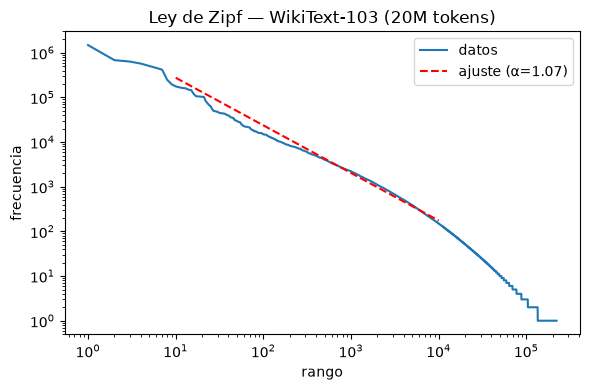

top-10: [('the', 1485833), ('<num>', 683816), ('of', 636502), ('and', 572665), ('in', 506862), ('to', 458448), ('a', 417457), ('was', 247996), ('s', 196451), ('on', 176882)]


In [7]:
freqs = np.array(sorted(counts_all.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
# la cola (frecuencia 1-2) se aplana por discretización; ajustar sobre el rango 10..10^4
sel = (ranks >= 10) & (ranks <= 10_000)
slope, intercept = np.polyfit(np.log(ranks[sel]), np.log(freqs[sel]), 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ranks, freqs, label="datos")
ax.loglog(ranks[sel], np.exp(intercept) * ranks[sel] ** slope, "r--", label=f"ajuste (α={-slope:.2f})")
ax.set(xlabel="rango", ylabel="frecuencia", title="Ley de Zipf — WikiText-103 (20M tokens)")
ax.legend(); plt.tight_layout(); plt.savefig("zipf.png", dpi=150); plt.show()
print("top-10:", counts_all.most_common(10))

### 1.5 Tamaño del vocabulario vs `min_count`

In [8]:
total = sum(freqs)
rows = []
for mc in [1, 2, 5, 10, 20, 50, 100]:
    keep = freqs >= mc
    rows.append({"min_count": mc, "vocab": int(keep.sum()), "% tipos": round(100 * keep.mean(), 1),
                 "% tokens cubiertos": round(100 * freqs[keep].sum() / total, 2)})
mc_table = pd.DataFrame(rows)
mc_table

,min_count,vocab,% tipos,% tokens cubiertos
0,1,221106,100.0,100.00
1,2,134469,60.8,99.57
2,5,76975,34.8,98.80
3,10,52011,23.5,97.99
4,20,35271,16.0,96.84
5,50,20487,9.3,94.55
6,100,13172,6.0,91.98


La cola larga domina el vocabulario (~65% de los tipos aparece <5 veces) pero cubre una fracción
mínima de los tokens. `min_count=5` conserva ~99% del texto con una fracción del vocabulario: las palabras
más raras no tienen contextos suficientes para aprender un vector útil y solo agrandan la tabla de embeddings.

### 1.6 Vocabulario, IDs y submuestreo de palabras frecuentes

Submuestreo (Mikolov et al., 2013): cada ocurrencia de la palabra `w` se conserva con probabilidad
`P(w) = min(1, sqrt(t / f(w)) + t / f(w))`, con `f` la frecuencia relativa. Las palabras muy frecuentes
(`the`, `of`) aportan poca información por ocurrencia y consumirían la mayor parte del cómputo.

In [9]:
itos = [w for w, c in counts_all.most_common() if c >= MIN_COUNT]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
ids = np.array([stoi[t] for t in tokens if t in stoi], dtype=np.int32)
cnt = np.array([counts_all[w] for w in itos], dtype=np.float64)
freq = cnt / cnt.sum()
print(f"V={V:,} | corpus en IDs: {len(ids):,}")

SUBSAMPLE_T = 1e-4  # t=1e-5 es lo típico para corpus de miles de millones de tokens; 1e-4 para 20M
def keep_prob(freq, t=SUBSAMPLE_T):
    return np.minimum(1.0, np.sqrt(t / freq) + t / freq)

kp = keep_prob(freq)
exp_kept = (kp[ids]).mean()
print(f"fracción esperada de tokens conservados por época: {exp_kept:.1%}")
print(pd.DataFrame({"palabra": itos[:8], "freq": freq[:8].round(4), "P(conservar)": kp[:8].round(3)}).to_string(index=False))

V=76,975 | corpus en IDs: 19,760,936
fracción esperada de tokens conservados por época: 57.3%
palabra   freq  P(conservar)
    the 0.0752         0.038
  <num> 0.0346         0.057
     of 0.0322         0.059
    and 0.0290         0.062
     in 0.0256         0.066
     to 0.0232         0.070
      a 0.0211         0.074
    was 0.0125         0.097


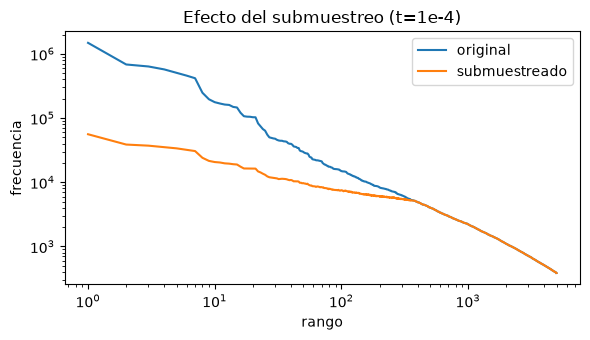

19,760,936 -> 11,318,787 tokens (57.3%); 'the': 1,485,833 -> 55,989


In [10]:
rng = np.random.default_rng(SEED)
sub = ids[rng.random(len(ids)) < kp[ids]]
c0 = np.bincount(ids, minlength=V); c1 = np.bincount(sub, minlength=V)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(np.arange(1, 5001), c0[:5000], label="original")
ax.loglog(np.arange(1, 5001), c1[:5000], label="submuestreado")
ax.set(xlabel="rango", ylabel="frecuencia", title="Efecto del submuestreo (t=1e-4)")
ax.legend(); plt.tight_layout(); plt.savefig("subsampling.png", dpi=150); plt.show()
print(f"{len(ids):,} -> {len(sub):,} tokens ({len(sub)/len(ids):.1%}); 'the': {c0[stoi['the']]:,} -> {c1[stoi['the']]:,}")

## Fase 2 — Construcción y entrenamiento de embeddings

### 2.0 Evaluación: WordSim-353, SimLex-999 y analogías (3CosAdd)

Todos los modelos se exponen como `gensim.KeyedVectors` (misma interfaz para el SGNS propio, gensim y GloVe).

- **Similitud:** correlación de Spearman entre el coseno del modelo y el puntaje humano (pares con OOV se omiten).
- **Analogías:** 3CosAdd propio, `argmax_d cos(d, b) − cos(d, a) + cos(d, c)` excluyendo `a, b, c`, sobre las
  30 000 palabras más frecuentes. Preguntas con alguna palabra fuera de ese vocabulario se omiten (se reporta cobertura).
  Las 5 primeras categorías de `questions-words.txt` son semánticas y las 9 restantes sintácticas.

In [11]:
def load_analogies(path="data/questions-words.txt"):
    sections, cur = {}, None
    for line in open(path):
        if line.startswith(":"):
            cur = line[1:].strip(); sections[cur] = []
        else:
            sections[cur].append(tuple(line.lower().split()))
    return sections

ANALOGIES = load_analogies()
SEM = list(ANALOGIES)[:5]
print(len(ANALOGIES), "categorías;", sum(map(len, ANALOGIES.values())), "preguntas")

def analogy_eval(kv, restrict=30_000, sections=ANALOGIES):
    """3CosAdd. Devuelve dict categoría -> (aciertos, evaluadas, total)."""
    n = min(restrict, len(kv.index_to_key))
    E = torch.from_numpy(kv.vectors[:n]).float()
    E = F.normalize(E, dim=1)
    out = {}
    for name, qs in sections.items():
        idx = [[kv.key_to_index.get(w, n) for w in q] for q in qs]
        idx = torch.tensor([q for q in idx if max(q) < n])
        if len(idx) == 0:
            out[name] = (0, 0, len(qs)); continue
        a, b, c, d = idx.T
        scores = (E[b] - E[a] + E[c]) @ E.T
        scores.scatter_(1, torch.stack([a, b, c], 1), -1e9)  # excluir las palabras de la pregunta
        out[name] = (int((scores.argmax(1) == d).sum()), len(idx), len(qs))
    return out

def analogy_acc(res, names=None):
    names = names or list(res)
    hit = sum(res[n][0] for n in names); tot = sum(res[n][1] for n in names)
    return hit / tot if tot else float("nan")

def evaluate(kv):
    ws = kv.evaluate_word_pairs("data/wordsim353.tsv", dummy4unknown=False)
    sl = kv.evaluate_word_pairs("data/simlex999.txt", dummy4unknown=False)
    an = analogy_eval(kv)
    return {"WS353": ws[1][0], "SimLex": sl[1][0], "ana_total": analogy_acc(an),
            "ana_sem": analogy_acc(an, SEM), "ana_syn": analogy_acc(an, [s for s in an if s not in SEM])}

def to_kv(E, keys):
    kv = KeyedVectors(E.shape[1]); kv.add_vectors(keys, E); return kv

14 categorías; 19544 preguntas


### 2.1 Skip-gram con Negative Sampling desde cero (PyTorch)

Dos tablas `nn.Embedding` (entrada `v_c` y salida `u_o`). Para un par (centro `c`, contexto `o`) y `K` negativos
`n_k ~ P_n(w) ∝ f(w)^0.75`:

`L = −log σ(u_o · v_c) − Σ_k log σ(−u_{n_k} · v_c)`

Decisiones de diseño:
- **Ventana dinámica:** el radio se sortea uniforme en `[1, W]` para cada centro (pesa más a los contextos cercanos, como word2vec).
- **Submuestreo** re-muestreado en cada época (sección 1.6).
- **Tablas `sparse=True` + `SparseAdam`:** en cada paso solo se actualizan las filas usadas (vocab de 77k).
- **Pares generados vectorizados** con numpy (un desplazamiento `d` por pasada), mezclados y servidos en mini-batches de 8192.
- Los vectores finales son la tabla de entrada `v` (como en word2vec).

In [12]:
class SGNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d, sparse=True)
        self.out = nn.Embedding(V, d, sparse=True)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d)
        nn.init.zeros_(self.out.weight)

    def forward(self, c, o, neg):
        v = self.inp(c)                                         # B,d
        pos = F.logsigmoid((v * self.out(o)).sum(-1))           # B
        negs = F.logsigmoid(-torch.bmm(self.out(neg), v.unsqueeze(-1)).squeeze(-1)).sum(-1)  # B,K -> B
        return -(pos + negs).mean()


def make_pairs(ids, keep, window, rng):
    """Una época de pares (centro, contexto): submuestreo + ventana dinámica."""
    s = ids[rng.random(len(ids)) < keep[ids]]
    b = rng.integers(1, window + 1, len(s))
    C, O = [], []
    for d in range(1, window + 1):
        m = b[:-d] >= d;  C.append(s[:-d][m]); O.append(s[d:][m])      # contexto a la derecha
        m = b[d:] >= d;   C.append(s[d:][m]);  O.append(s[:-d][m])     # contexto a la izquierda
    C, O = np.concatenate(C), np.concatenate(O)
    p = rng.permutation(len(C))
    return torch.from_numpy(C[p]).long(), torch.from_numpy(O[p]).long()


def train_sgns(tag, dim=100, window=5, neg=5, epochs=3, lr=3e-3, batch=8192, ids=ids, verbose=True):
    path = DATA / "vectors" / f"{tag}.kv"
    if path.exists():
        return KeyedVectors.load(str(path))
    rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
    model = SGNS(V, dim).to(DEVICE)
    opt = torch.optim.SparseAdam(model.parameters(), lr=lr)
    noise = torch.from_numpy(cnt ** 0.75); cdf = (noise / noise.sum()).cumsum(0).float()
    for ep in range(epochs):
        C, O = make_pairs(ids, kp, window, rng)
        n_steps = len(C) // batch; t0 = time.time(); run = 0.0
        for i in range(n_steps):
            lr_now = lr * max(0.05, 1 - (ep + i / n_steps) / epochs)  # decaimiento lineal global
            for g in opt.param_groups: g["lr"] = lr_now
            sl = slice(i * batch, (i + 1) * batch)
            negs = torch.searchsorted(cdf, torch.rand(batch, neg)).clamp_(max=V - 1)  # ~ f^0.75
            loss = model(C[sl].to(DEVICE), O[sl].to(DEVICE), negs.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            run += loss.item() if i % 50 == 0 else 0
        kv = to_kv(model.inp.weight.detach().cpu().numpy(), itos)
        if verbose:
            print(f"[{tag}] ep {ep+1}/{epochs} | {len(C):,} pares | loss~{run/(n_steps/50):.3f} | "
                  f"{time.time()-t0:.0f}s | {({k: round(v, 3) for k, v in evaluate(kv).items()})}")
    kv.save(str(path)); return kv

sgns = train_sgns("sgns_w5")

### 2.2 Word2Vec de gensim (referencia)

Mismo corpus, mismos hiperparámetros (`sg=1`, `dim=100`, `window=5`, `negative=5`, `sample=1e-4`, `min_count=5`,
3 épocas). Si el SGNS propio está bien implementado, debe quedar cerca de gensim.

In [13]:
def sentences(toks, size=1000):
    return [toks[i:i + size] for i in range(0, len(toks), size)]

def train_gensim(tag, toks=None, vector_size=100, window=5, negative=5, alpha=0.025, epochs=3, sg=1, sample=SUBSAMPLE_T, save=False):
    path = DATA / "vectors" / f"{tag}.kv"
    if path.exists():
        return KeyedVectors.load(str(path))
    with contextlib.redirect_stderr(io.StringIO()):  # gensim imprime 'Exception ignored in our_dot_float' (scipy BLAS), inocuo
      m = Word2Vec(sentences(tokens if toks is None else toks), vector_size=vector_size, window=window, negative=negative,
                   alpha=alpha, epochs=epochs, sg=sg, sample=sample, min_count=MIN_COUNT, workers=N_WORKERS, seed=SEED)
    if save: m.wv.save(str(path))
    return m.wv

t0 = time.time()
w2v = train_gensim("gensim_w5", save=True)
print(f"gensim: {len(w2v):,} palabras en {time.time()-t0:.0f}s")

gensim: 76,975 palabras en 0s


### 2.3 GloVe preentrenado (`glove-wiki-gigaword-100`, sin entrenamiento adicional)

In [14]:
glove = api.load("glove-wiki-gigaword-100")
print(glove.vectors.shape)

(400000, 100)


### 2.4 Comparación de los tres modelos

In [15]:
models = {"SGNS propio (PyTorch)": sgns, "Word2Vec gensim": w2v, "GloVe 100d (preentrenado)": glove}
cmp = pd.DataFrame({k: evaluate(v) for k, v in models.items()}).T
cmp.insert(0, "vocab", [len(v.index_to_key) for v in models.values()])
cmp.round(3)

,vocab,WS353,SimLex,ana_total,ana_sem,ana_syn
SGNS propio (PyTorch),76975,0.632,0.292,0.330,0.250,0.367
Word2Vec gensim,76975,0.619,0.305,0.313,0.209,0.362
GloVe 100d (preentrenado),400000,0.533,0.296,0.655,0.655,0.655


### 2.5 Exploración de hiperparámetros

Barrido de un factor a la vez (resto en la configuración base: dim 100, ventana 5, 5 negativos, lr 0.025,
3 épocas en el modelo principal, `sample=1e-4`). Para que el barrido sea barato se usa gensim sobre un prefijo de 5M tokens con 10 épocas (con 3 el corpus chico queda sub-entrenado
y las comparaciones se vuelven ruido); el tamaño del corpus se barre aparte (1M / 5M / 20M, 5 épocas cada uno). El efecto de la **ventana** se confirma además con el
SGNS propio en el corpus completo (2.6).

In [16]:
SWEEP_TOKENS = tokens[:5_000_000]
sweeps = {
    "dim":      [("vector_size", v) for v in (50, 100, 200, 300)],
    "ventana":  [("window", v) for v in (2, 5, 10)],
    "negativos": [("negative", v) for v in (2, 5, 15)],
    "lr (alpha)": [("alpha", v) for v in (0.005, 0.025, 0.05)],
}
rows = []
for factor, opts in sweeps.items():
    for param, val in opts:
        kv = train_gensim(f"sweep_{param}_{val}", toks=SWEEP_TOKENS, epochs=10, **{param: val})
        rows.append({"factor": factor, "valor": val, "corpus": "5M", **evaluate(kv)})
for n in (1_000_000, 5_000_000, 20_000_000):
    kv = train_gensim(f"sweep_corpus_{n}", toks=tokens[:n], epochs=5)
    rows.append({"factor": "tamaño corpus", "valor": f"{n//10**6}M", "corpus": f"{n//10**6}M", **evaluate(kv)})
sweep = pd.DataFrame(rows)
sweep.drop(columns="corpus").round(3)

,factor,valor,WS353,SimLex,ana_total,ana_sem,ana_syn
0,dim,50,0.560,0.227,0.160,0.106,0.182
1,dim,100,0.574,0.260,0.194,0.131,0.219
2,dim,200,0.580,0.271,0.172,0.117,0.194
3,dim,300,0.581,0.256,0.154,0.089,0.179
4,ventana,2,0.539,0.248,0.159,0.101,0.182
5,ventana,5,0.583,0.249,0.192,0.128,0.217
6,ventana,10,0.630,0.241,0.204,0.158,0.222
7,negativos,2,0.597,0.249,0.160,0.101,0.183
8,negativos,5,0.588,0.262,0.185,0.126,0.208
9,negativos,15,0.581,0.242,0.205,0.157,0.224


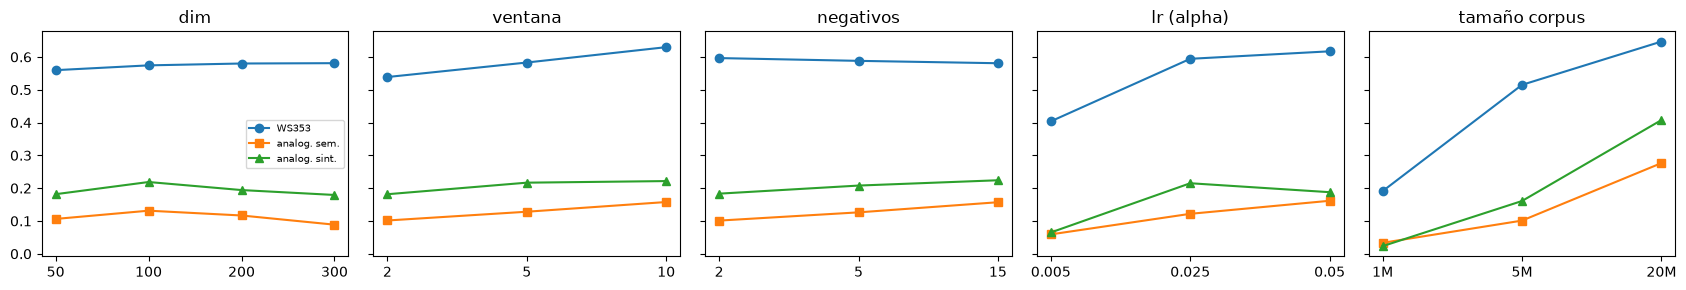

In [17]:
fig, axs = plt.subplots(1, 5, figsize=(17, 3), sharey=True)
for ax, (factor, g) in zip(axs, sweep.groupby("factor", sort=False)):
    x = g["valor"].astype(str)
    ax.plot(x, g["WS353"], "o-", label="WS353"); ax.plot(x, g["ana_sem"], "s-", label="analog. sem.")
    ax.plot(x, g["ana_syn"], "^-", label="analog. sint.")
    ax.set_title(factor)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("hyperparams.png", dpi=150); plt.show()

### 2.6 Ventana pequeña vs grande con el SGNS propio (corpus completo)

Ventana chica (2) captura relaciones **sintácticas/funcionales** (vecinos inmediatos intercambiables: mismo POS);
ventana grande (10) captura relaciones **temáticas/semánticas** (palabras del mismo tema co-ocurren a distancia).

In [18]:
sgns_w2 = train_sgns("sgns_w2", window=2)
sgns_w10 = train_sgns("sgns_w10", window=10)
win = pd.DataFrame({f"SGNS ventana {w}": evaluate(kv) for w, kv in [(2, sgns_w2), (5, sgns), (10, sgns_w10)]}).T
win.round(3)

,WS353,SimLex,ana_total,ana_sem,ana_syn
SGNS ventana 2,0.594,0.297,0.294,0.184,0.345
SGNS ventana 5,0.632,0.292,0.330,0.250,0.367
SGNS ventana 10,0.631,0.297,0.356,0.295,0.384


## Fase 3 — Aritmética vectorial

### 3.1 Analogías con 3CosAdd

`vec(b) − vec(a) + vec(c) ≈ vec(d)`; ej. `king − man + woman ≈ queen`. La búsqueda excluye `a`, `b`, `c`.

In [19]:
def analogy(kv, a, b, c, topn=5, restrict=30_000):
    """a es a b como c es a ?  (3CosAdd)"""
    E = F.normalize(torch.from_numpy(kv.vectors[:restrict]).float(), dim=1)
    q = E[kv.key_to_index[b]] - E[kv.key_to_index[a]] + E[kv.key_to_index[c]]
    s = E @ q
    for w in (a, b, c): s[kv.key_to_index[w]] = -1e9
    return [kv.index_to_key[i] for i in s.topk(topn).indices]

tests = [("man", "king", "woman"), ("france", "paris", "italy"), ("walk", "walking", "swim"),
         ("good", "better", "bad"), ("japan", "tokyo", "germany"), ("dollar", "usa", "yen")]
rows = []
for a, b, c in tests:
    row = {"a : b :: c : ?": f"{a} : {b} :: {c} : ?"}
    for name, kv in models.items():
        try: row[name] = ", ".join(analogy(kv, a, b, c, 3))
        except KeyError: row[name] = "(OOV)"
    rows.append(row)
pd.DataFrame(rows).set_index("a : b :: c : ?")

,SGNS propio (PyTorch),Word2Vec gensim,GloVe 100d (preentrenado)
a : b :: c : ?,,,
man : king :: woman : ?,"consort, queen, castile","queen, consort, thelwulf","queen, monarch, throne"
france : paris :: italy : ?,"vienna, prague, venice","vienna, milan, prague","rome, milan, naples"
walk : walking :: swim : ?,"swimming, swam, bathing","swam, moonlight, bathing","swimming, surfing, swam"
good : better :: bad : ?,"bigger, worse, happier","bigger, worse, fared","worse, too, even"
japan : tokyo :: germany : ?,"berlin, munich, frankfurt","frankfurt, berlin, budapest","frankfurt, berlin, munich"
dollar : usa :: yen : ?,"moto, nhk, yahoo","bish, nhk, osaka","u.s.a., wisconsin, aus"


### 3.2 Evaluación sistemática en las 14 categorías de `questions-words.txt`

In [20]:
all_models = {"SGNS w=5 (propio)": sgns, "SGNS w=2": sgns_w2, "SGNS w=10": sgns_w10,
              "gensim w2v": w2v, "GloVe-100": glove}
per_cat = {n: analogy_eval(kv) for n, kv in all_models.items()}
tab = pd.DataFrame({n: {c: (r[c][0] / r[c][1] if r[c][1] else np.nan) for c in ANALOGIES} for n, r in per_cat.items()})
tab.loc["— semántico"] = {n: analogy_acc(r, SEM) for n, r in per_cat.items()}
tab.loc["— sintáctico"] = {n: analogy_acc(r, [c for c in r if c not in SEM]) for n, r in per_cat.items()}
tab.loc["TOTAL"] = {n: analogy_acc(r) for n, r in per_cat.items()}
tab.loc["cobertura"] = {n: sum(v[1] for v in r.values()) / sum(v[2] for v in r.values()) for n, r in per_cat.items()}
tab.round(3)

,SGNS w=5 (propio),SGNS w=2,SGNS w=10,gensim w2v,GloVe-100
capital-common-countries,0.412,0.257,0.526,0.348,0.943
capital-world,0.285,0.165,0.369,0.194,0.894
currency,0.000,0.000,0.011,0.000,0.178
city-in-state,0.171,0.132,0.195,0.152,0.312
family,0.421,0.494,0.377,0.462,0.877
gram1-adjective-to-adverb,0.063,0.055,0.086,0.078,0.221
gram2-opposite,0.082,0.065,0.065,0.075,0.234
gram3-comparative,0.392,0.480,0.335,0.462,0.794
gram4-superlative,0.251,0.316,0.207,0.278,0.598
gram5-present-participle,0.309,0.304,0.330,0.334,0.695


propio: 0.3299 | gensim.evaluate_word_analogies: 0.3299


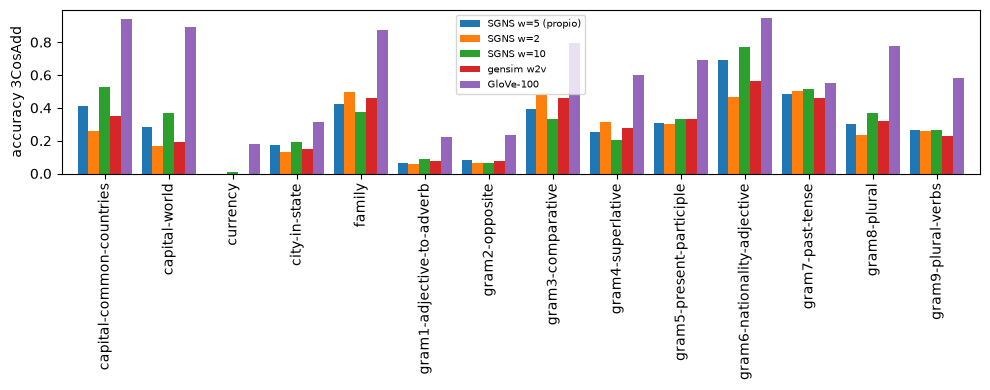

In [21]:
# sanity check del 3CosAdd propio contra la implementación de gensim (mismo vocab restringido)
g_acc, _ = sgns.evaluate_word_analogies("data/questions-words.txt", restrict_vocab=30_000, case_insensitive=True)
print(f"propio: {analogy_acc(per_cat['SGNS w=5 (propio)']):.4f} | gensim.evaluate_word_analogies: {g_acc:.4f}")
fig, ax = plt.subplots(figsize=(10, 4))
tab.iloc[:14].plot.bar(ax=ax, width=0.85); ax.set_ylabel("accuracy 3CosAdd"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("analogies_by_cat.png", dpi=150); plt.show()

### 3.3 Visualización de clusters semánticos (t-SNE)

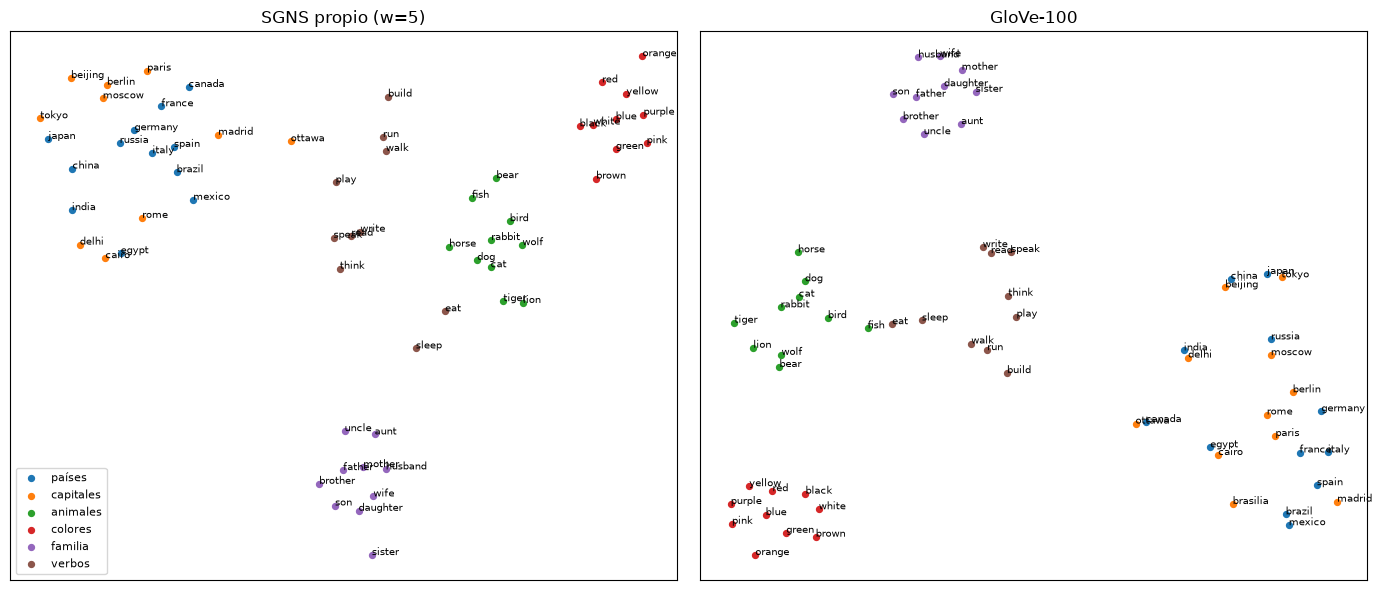

In [22]:
from sklearn.manifold import TSNE
groups = {
    "países": "france germany italy spain china japan russia india brazil canada egypt mexico".split(),
    "capitales": "paris berlin rome madrid beijing tokyo moscow delhi brasilia ottawa cairo".split(),
    "animales": "dog cat horse lion tiger bird fish wolf bear rabbit".split(),
    "colores": "red blue green yellow black white orange purple brown pink".split(),
    "familia": "father mother brother sister son daughter uncle aunt husband wife".split(),
    "verbos": "run walk eat sleep write read speak think build play".split(),
}
def tsne_plot(kv, ax, title):
    words = [(w, g) for g, ws in groups.items() for w in ws if w in kv.key_to_index]
    X = np.stack([kv[w] for w, _ in words])
    Y = TSNE(2, perplexity=12, init="pca", random_state=SEED).fit_transform(X)
    for g in groups:
        pts = [(y, w) for y, (w, gg) in zip(Y, words) if gg == g]
        ax.scatter(*np.array([p for p, _ in pts]).T, s=18, label=g)
        for p, w in pts: ax.annotate(w, p, fontsize=7)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
tsne_plot(sgns, axs[0], "SGNS propio (w=5)"); tsne_plot(glove, axs[1], "GloVe-100")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.savefig("tsne.png", dpi=150); plt.show()

In [23]:
# vectores del mejor modelo propio (.kv y .txt) para el entregable
best = sgns
best.save("data/vectors/best_sgns.kv"); best.save_word2vec_format("data/vectors/best_sgns.txt")
print("guardado: data/vectors/best_sgns.kv / .txt", best.vectors.shape)

guardado: data/vectors/best_sgns.kv / .txt (76975, 100)


## Fase 4 — Pipeline end-to-end: clasificación de AG News

Cuatro familias de modelos sobre las 4 clases (World, Sports, Business, Sci/Tech):

1. **Baseline:** TF-IDF (unigramas + bigramas) + Regresión Logística.
2. **Embeddings aleatorios:** `nn.EmbeddingBag` (media) + MLP, entrenado desde cero.
3. **SGNS propio** como inicialización de la tabla: (a) congelada, (b) con fine-tuning.
4. **GloVe-100** como inicialización: (a) congelada, (b) con fine-tuning.

Todos los modelos neuronales comparten arquitectura (`EmbeddingBag` media → Linear(128) → ReLU → Dropout → Linear(4))
y vocabulario (palabras con ≥2 apariciones en el train de AG News). Las filas sin vector preentrenado se inicializan
con ruido pequeño (fine-tuning) o en cero (congelada). Split: 108k train / 12k val (para elegir época) / 7.6k test oficial.
Se reportan media ± desviación sobre 3 semillas.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

ag = load_dataset("fancyzhx/ag_news")
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
perm = np.random.default_rng(SEED).permutation(len(ag["train"]))
val_idx, tr_idx = perm[:12_000], perm[12_000:]
tok_tr = [tokenize(t) for t in ag["train"]["text"]]
tok_te = [tokenize(t) for t in ag["test"]["text"]]
y_all = np.array(ag["train"]["label"]); y_te = np.array(ag["test"]["label"])
print(len(tr_idx), len(val_idx), len(tok_te), "| ejemplo:", " ".join(tok_tr[0][:15]), "->", LABELS[y_all[0]])

def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return {"acc": accuracy_score(y, p), "prec": pr, "rec": rc, "f1": f1}

108000 12000 7600 | ejemplo: wall st bears claw back into the black reuters reuters short sellers wall street's dwindling -> Business


### 4.1 Baseline: TF-IDF + Regresión Logística

In [25]:
def tfidf_lr(n_train=None):
    idx = tr_idx if n_train is None else tr_idx[:n_train]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X = vec.fit_transform([" ".join(tok_tr[i]) for i in idx])
    clf = LogisticRegression(C=10, max_iter=1000).fit(X, y_all[idx])
    return metrics(y_te, clf.predict(vec.transform([" ".join(t) for t in tok_te])))

t0 = time.time(); res_tfidf = tfidf_lr(); res_tfidf_small = tfidf_lr(1000)
print(f"TF-IDF+LR ({time.time()-t0:.0f}s):", {k: round(v, 4) for k, v in res_tfidf.items()})
print("TF-IDF+LR con 1000 ejemplos:", {k: round(v, 4) for k, v in res_tfidf_small.items()})

TF-IDF+LR (20s): {'acc': 0.9224, 'prec': 0.9222, 'rec': 0.9224, 'f1': 0.9222}
TF-IDF+LR con 1000 ejemplos: {'acc': 0.8238, 'prec': 0.8228, 'rec': 0.8238, 'f1': 0.8229}


### 4.2 Clasificadores con `EmbeddingBag`

Vocabulario de AG News y matrices de inicialización a partir de cada modelo de embeddings.

In [26]:
cnt_ag = collections.Counter(w for i in tr_idx for w in tok_tr[i])
ag_itos = [w for w, c in cnt_ag.most_common() if c >= 2]
ag_stoi = {w: i for i, w in enumerate(ag_itos)}
to_ids = lambda toks: np.array([ag_stoi[w] for w in toks if w in ag_stoi], dtype=np.int64)
ids_tr = [to_ids(t) for t in tok_tr]; ids_te = [to_ids(t) for t in tok_te]
print(f"vocab AG News: {len(ag_itos):,} | tokens/doc: {np.mean([len(x) for x in ids_tr]):.1f}")

def init_table(kv, dim=100, seed=SEED, noise=0.1):
    """Matriz (V_ag, dim). kv=None -> aleatoria. Palabras sin vector -> ruido (noise>0) o ceros."""
    rng = np.random.default_rng(seed)
    W = rng.normal(0, noise, (len(ag_itos), dim)).astype(np.float32) if noise else np.zeros((len(ag_itos), dim), np.float32)
    if kv is None:
        return W, 0.0
    hit = [(i, kv.key_to_index[w]) for i, w in enumerate(ag_itos) if w in kv.key_to_index]
    W[[i for i, _ in hit]] = kv.vectors[[j for _, j in hit]]
    return W, len(hit) / len(ag_itos)

for name, kv in [("SGNS", sgns), ("GloVe", glove)]:
    print(f"{name}: cobertura del vocab AG News = {init_table(kv)[1]:.1%}")

vocab AG News: 41,889 | tokens/doc: 39.3
SGNS: cobertura del vocab AG News = 71.5%
GloVe: cobertura del vocab AG News = 93.1%


In [27]:
class BagClf(nn.Module):
    def __init__(self, W0, freeze, hid=128):
        super().__init__()
        self.emb = nn.EmbeddingBag.from_pretrained(torch.from_numpy(W0), freeze=freeze, mode="mean")
        self.mlp = nn.Sequential(nn.Linear(W0.shape[1], hid), nn.ReLU(), nn.Dropout(0.3), nn.Linear(hid, 4))

    def forward(self, flat, offs):
        return self.mlp(self.emb(flat, offs))

def batch(docs, idx):
    seqs = [docs[i] for i in idx]
    lens = torch.tensor([len(s) for s in seqs])
    offs = torch.cat([torch.zeros(1, dtype=torch.long), lens.cumsum(0)[:-1]])
    return torch.from_numpy(np.concatenate(seqs)), offs

@torch.no_grad()
def predict(model, docs, bs=2048):
    model.eval()
    return np.concatenate([model(*batch(docs, range(i, min(i + bs, len(docs))))).argmax(1).numpy()
                           for i in range(0, len(docs), bs)])

def run_clf(W0, freeze, seed, n_train=None, epochs=10, lr=2e-3, bs=256):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    idx = tr_idx if n_train is None else tr_idx[:n_train]
    model = BagClf(W0.copy(), freeze)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    y_tr_t = torch.from_numpy(y_all)
    ids_val = [ids_tr[i] for i in val_idx]; y_val = y_all[val_idx]
    best = (-1, None)
    for ep in range(epochs):
        model.train()
        for b in np.array_split(rng.permutation(idx), max(1, len(idx) // bs)):
            loss = F.cross_entropy(model(*batch(ids_tr, b)), y_tr_t[b])
            opt.zero_grad(); loss.backward(); opt.step()
        va = accuracy_score(y_val, predict(model, ids_val))
        if va > best[0]:
            best = (va, metrics(y_te, predict(model, ids_te)))  # test en la mejor época de validación
    return best[1]

VARIANTS = {"Embeddings aleatorios": (None, False), "SGNS frozen": (sgns, True), "SGNS fine-tune": (sgns, False),
            "GloVe frozen": (glove, True), "GloVe fine-tune": (glove, False)}

def run_all(n_train=None, epochs=10, seeds=(0, 1, 2)):
    out = {}
    for name, (kv, freeze) in VARIANTS.items():
        # frozen: filas sin vector en cero; fine-tune/aleatorio: ruido pequeño
        W0, _ = init_table(kv, noise=0.0 if (freeze and kv is not None) else 0.1)
        runs = [run_clf(W0, freeze, s, n_train, epochs) for s in seeds]
        out[name] = {k: (np.mean([r[k] for r in runs]), np.std([r[k] for r in runs])) for k in runs[0]}
        print(f"{name:22s} acc={out[name]['acc'][0]:.4f}±{out[name]['acc'][1]:.4f}")
    return out

def to_table(res, base):
    rows = {"TF-IDF + LogReg": {k: f"{v:.4f}" for k, v in base.items()}}
    rows.update({n: {k: f"{m:.4f} ± {s:.4f}" for k, (m, s) in r.items()} for n, r in res.items()})
    return pd.DataFrame(rows).T.rename(columns={"acc": "Accuracy", "prec": "Precision", "rec": "Recall", "f1": "F1"})

In [28]:
t0 = time.time()
res_full = run_all()
print(f"{time.time()-t0:.0f}s")
tab_full = to_table(res_full, res_tfidf); tab_full

Embeddings aleatorios  acc=0.9175±0.0011


SGNS frozen            acc=0.8753±0.0008


SGNS fine-tune         acc=0.9181±0.0005


GloVe frozen           acc=0.8954±0.0007


GloVe fine-tune        acc=0.9186±0.0006
113s


,Accuracy,Precision,Recall,F1
TF-IDF + LogReg,0.9224,0.9222,0.9224,0.9222
Embeddings aleatorios,0.9175 ± 0.0011,0.9176 ± 0.0010,0.9175 ± 0.0011,0.9174 ± 0.0011
SGNS frozen,0.8753 ± 0.0008,0.8760 ± 0.0008,0.8753 ± 0.0008,0.8753 ± 0.0008
SGNS fine-tune,0.9181 ± 0.0005,0.9185 ± 0.0009,0.9181 ± 0.0005,0.9179 ± 0.0006
GloVe frozen,0.8954 ± 0.0007,0.8957 ± 0.0004,0.8954 ± 0.0007,0.8952 ± 0.0007
GloVe fine-tune,0.9186 ± 0.0006,0.9191 ± 0.0005,0.9186 ± 0.0006,0.9185 ± 0.0006


### 4.3 Régimen de pocos datos (1 000 ejemplos etiquetados)

Es donde el conocimiento preentrenado debería aportar más: con pocos ejemplos, una tabla aleatoria no
puede aprender representaciones útiles de las palabras.

In [29]:
res_small = run_all(n_train=1000, epochs=30)
tab_small = to_table(res_small, res_tfidf_small); tab_small

Embeddings aleatorios  acc=0.8250±0.0020


SGNS frozen            acc=0.8357±0.0006


SGNS fine-tune         acc=0.8606±0.0012


GloVe frozen           acc=0.8656±0.0004


GloVe fine-tune        acc=0.8690±0.0015


,Accuracy,Precision,Recall,F1
TF-IDF + LogReg,0.8238,0.8228,0.8238,0.8229
Embeddings aleatorios,0.8250 ± 0.0020,0.8240 ± 0.0021,0.8250 ± 0.0020,0.8240 ± 0.0023
SGNS frozen,0.8357 ± 0.0006,0.8349 ± 0.0007,0.8357 ± 0.0006,0.8350 ± 0.0005
SGNS fine-tune,0.8606 ± 0.0012,0.8600 ± 0.0013,0.8606 ± 0.0012,0.8601 ± 0.0013
GloVe frozen,0.8656 ± 0.0004,0.8650 ± 0.0005,0.8656 ± 0.0004,0.8651 ± 0.0005
GloVe fine-tune,0.8690 ± 0.0015,0.8686 ± 0.0014,0.8690 ± 0.0015,0.8687 ± 0.0015


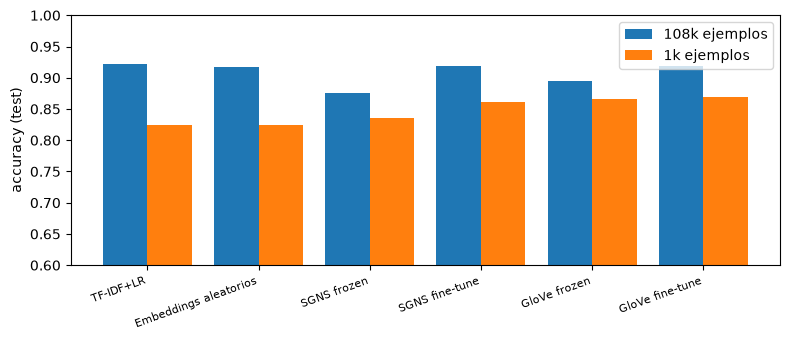

In [30]:
fig, ax = plt.subplots(figsize=(8, 3.5))
names = list(res_full); x = np.arange(len(names) + 1)
ax.bar(x - 0.2, [res_tfidf["acc"]] + [res_full[n]["acc"][0] for n in names], 0.4, label="108k ejemplos")
ax.bar(x + 0.2, [res_tfidf_small["acc"]] + [res_small[n]["acc"][0] for n in names], 0.4, label="1k ejemplos")
ax.set_xticks(x); ax.set_xticklabels(["TF-IDF+LR"] + names, rotation=20, ha="right", fontsize=8)
ax.set_ylim(0.6, 1); ax.set_ylabel("accuracy (test)"); ax.legend(); plt.tight_layout()
plt.savefig("classification.png", dpi=150); plt.show()